# Comparar

A mesma reta do caderno 01. Muda só a entrada.


In [1]:
# Mesmo arquivo e o mesmo corte de dias do caderno 01.
import os
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

import pandas as pd
import mlflow
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

mlflow.set_tracking_uri("mlruns")
mlflow.set_experiment("cerveja")

dataset = pd.read_csv("dados/Consumo_cerveja.csv")
y = dataset["Consumo de cerveja (litros)"].to_numpy()


/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**v1**: só a temperatura. É a reta do caderno 01.


In [2]:
# Uma coluna de entrada. O print é o MAE e o R² nos dias que ficaram de fora.
colunas = ["Temperatura Maxima (C)"]
X = dataset[colunas].to_numpy()
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=0)
modelo = LinearRegression().fit(X_treino, y_treino)
previsto = modelo.predict(X_teste)
mae = mean_absolute_error(y_teste, previsto)
r2 = r2_score(y_teste, previsto)
print("mae", round(mae, 3))
print("r2", round(r2, 3))

# log_input preenche a coluna Dataset. log_model preenche a coluna Models.
with mlflow.start_run(run_name="v1-temperatura"):
    mlflow.log_param("entradas", "Temperatura Maxima (C)")
    mlflow.log_metrics({"mae": mae, "r2": r2})
    mlflow.log_input(
        mlflow.data.from_pandas(dataset, source="dados/Consumo_cerveja.csv", name="cerveja"),
        context="training",
    )
    mlflow.sklearn.log_model(modelo, name="modelo")


mae 2.838
r2 0.262


/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/data/dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have mi

**v2**: temperatura e fim de semana (1 se sábado ou domingo).


In [3]:
colunas = ["Temperatura Maxima (C)", "Final de Semana"]
X = dataset[colunas].to_numpy()
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=0)
modelo = LinearRegression().fit(X_treino, y_treino)
previsto = modelo.predict(X_teste)
mae = mean_absolute_error(y_teste, previsto)
r2 = r2_score(y_teste, previsto)
print("mae", round(mae, 3))
print("r2", round(r2, 3))

with mlflow.start_run(run_name="v2-fim-de-semana"):
    mlflow.log_param("entradas", "Temperatura Maxima (C), Final de Semana")
    mlflow.log_metrics({"mae": mae, "r2": r2})
    mlflow.log_input(
        mlflow.data.from_pandas(dataset, source="dados/Consumo_cerveja.csv", name="cerveja"),
        context="training",
    )
    mlflow.sklearn.log_model(modelo, name="modelo")


/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/data/dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have mi

mae 2.055
r2 0.64


2026/10/08 20:05:38 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


**v3**: as duas de cima, mais a chuva em mm.


In [4]:
colunas = ["Temperatura Maxima (C)", "Final de Semana", "Precipitacao (mm)"]
X = dataset[colunas].to_numpy()
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=0)
modelo = LinearRegression().fit(X_treino, y_treino)
previsto = modelo.predict(X_teste)
mae = mean_absolute_error(y_teste, previsto)
r2 = r2_score(y_teste, previsto)
print("mae", round(mae, 3))
print("r2", round(r2, 3))

with mlflow.start_run(run_name="v3-chuva"):
    mlflow.log_param("entradas", "Temperatura Maxima (C), Final de Semana, Precipitacao (mm)")
    mlflow.log_metrics({"mae": mae, "r2": r2})
    mlflow.log_input(
        mlflow.data.from_pandas(dataset, source="dados/Consumo_cerveja.csv", name="cerveja"),
        context="training",
    )
    mlflow.sklearn.log_model(modelo, name="modelo")


/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/data/dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
/Users/teixeirah/work/uri/Ciência de Dados/aula-ml-2/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have mi

mae 2.063
r2 0.657


2026/10/08 20:05:39 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Cada run gravou um MAE e um R². À esquerda o R² sobe quando a previsão acompanha mais o consumo. À direita o MAE desce quando o erro em litros diminui.


tags.mlflow.runName  metrics.mae  metrics.r2
     v1-temperatura        2.838       0.262
   v2-fim-de-semana        2.055       0.640
           v3-chuva        2.063       0.657


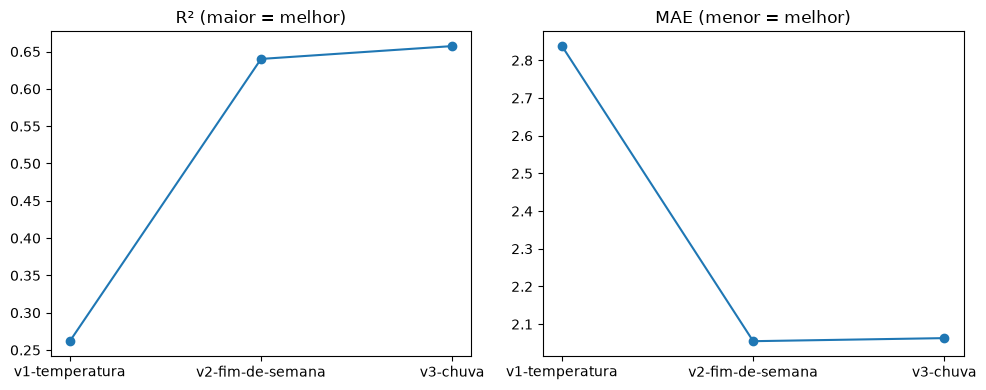

In [5]:
import matplotlib.pyplot as plt

runs = mlflow.search_runs(
    experiment_names=["cerveja"],
    filter_string="tags.mlflow.runName LIKE 'v%'",
    order_by=["start_time ASC"],
)
runs = runs.drop_duplicates("tags.mlflow.runName", keep="last")
print(runs[["tags.mlflow.runName", "metrics.mae", "metrics.r2"]].round(3).to_string(index=False))

nomes = runs["tags.mlflow.runName"]
fig, (ax_r2, ax_mae) = plt.subplots(1, 2, figsize=(10, 4))
ax_r2.plot(nomes, runs["metrics.r2"], marker="o")
ax_r2.set_title("R² (maior = melhor)")
ax_mae.plot(nomes, runs["metrics.mae"], marker="o")
ax_mae.set_title("MAE (menor = melhor)")
plt.tight_layout()
plt.show()


`MLFLOW_ALLOW_FILE_STORE=true mlflow ui --backend-store-uri mlruns`
